# Assignment 1: Data Profiling (EDA) Report: Hotel Booking Demand
**Course:** TTTC3213 Data Engineering

| Name | Matric No. |
|---|---|
| ZHANG LEZHI | A213960 |
| ZHU ZANLIN | A214008 |
| LU JIAYI | A214042 |
| LUO NA | A214087 |

**How to run this notebook**
1. Install the libraries: `pip install -r requirements.txt`
2. Open the notebook: `jupyter notebook assignment1_data_profiling.ipynb` (or upload it to Google Colab)
3. Click **Kernel → Restart & Run All**. The notebook reads `data/hotels.csv`; if the file is missing, it downloads it from the URL in Section 2.

## 1. Scenario
A hotel revenue team wants to use past booking records to study cancellations and to set room prices (ADR = Average Daily Rate). Booking data is typed in by guests, travel agents and hotel staff, so it contains blanks, typing errors, inconsistent categories, guest details that can identify people, and an unbalanced mix of guests, which matches the situation of this assignment.
**Our questions:** (1) Are the ADR values reliable enough to find a typical price for each hotel? (2) Can the data be used to study cancellations fairly across guest groups? (3) Can it be shared with analysts without exposing individual guests?

## 2. Data source
- **Dataset:** Hotel Booking Demand, from Antonio, Almeida & Nunes (2019), *Data in Brief*, 22, 41–49, https://doi.org/10.1016/j.dib.2018.11.126. Real bookings from two hotels in Portugal (one City Hotel, one Resort Hotel), arrivals from July 2015 to August 2017.
- **How we obtained it:** open dataset, downloaded as a CSV file from the TidyTuesday GitHub repository:
  https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2020/2020-02-11/hotels.csv
  (the same data is on Kaggle: https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand). No scraping was needed.
- A copy is saved in `data/hotels.csv` so the notebook also runs offline.

In [1]:
import os
import re
import hashlib
import secrets
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="colorblind")
pd.set_option("display.max_columns", 40)

URL = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2020/2020-02-11/hotels.csv"
LOCAL = "data/hotels.csv"

# use the local copy; download it only if it is not there
if not os.path.exists(LOCAL):
    os.makedirs("data", exist_ok=True)
    urllib.request.urlretrieve(URL, LOCAL)

## 3. Data profiling and issue handling
### 3.0 First look (size, types, spread, blanks)

In [2]:
df_raw = pd.read_csv(LOCAL)   # untouched copy, used for the before/after comparison
df = df_raw.copy()            # working copy that we clean
print("Shape:", df.shape)
df.head()

Shape: (119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
is_canceled,119390.0,0.370416,0.482918,0.00,0.00,0.000,1.0,1.0
lead_time,119390.0,104.011416,106.863097,0.00,18.00,69.000,160.0,737.0
arrival_date_year,119390.0,2016.156554,0.707476,2015.00,2016.00,2016.000,2017.0,2017.0
arrival_date_week_number,119390.0,27.165173,13.605138,1.00,16.00,28.000,38.0,53.0
arrival_date_day_of_month,119390.0,15.798241,8.780829,1.00,8.00,16.000,23.0,31.0
stays_in_weekend_nights,119390.0,0.927599,0.998613,0.00,0.00,1.000,2.0,19.0
stays_in_week_nights,119390.0,2.500302,1.908286,0.00,1.00,2.000,3.0,50.0
adults,119390.0,1.856403,0.579261,0.00,2.00,2.000,2.0,55.0
children,119386.0,0.103890,0.398561,0.00,0.00,0.000,0.0,10.0
babies,119390.0,0.007949,0.097436,0.00,0.00,0.000,0.0,10.0


**What we see:** 119,390 bookings × 32 columns.
- `children` is a float (should be a whole number), `agent` / `company` are ID codes stored as numbers.
- The arrival date is split into 3 columns (month is text) and `reservation_status_date` is text, not a date.
- `adr` has min **−6.38** and max **5,400**, and `adults` has min **0**: suspicious values to check.

### 3.1 Missing values

In [5]:
# read every cell as plain text to see how blanks are really written in the file
raw_text = pd.read_csv(LOCAL, dtype=str, keep_default_na=False)
tokens = ["", "NA", "NULL", "Undefined"]
hidden = pd.DataFrame({t: (raw_text == t).sum() for t in tokens})
hidden[hidden.sum(axis=1) > 0]

,,NA,NULL,Undefined
children,0,4,0,0
meal,0,0,0,1169
country,0,0,488,0
market_segment,0,0,0,2
distribution_channel,0,0,0,5
agent,0,0,16340,0
company,0,0,112593,0


Missing values are disguised as the text `NULL`, `NA` and `Undefined`. pandas turns `NULL` / `NA` into NaN automatically, but **not** `Undefined`, so `Undefined` is handled in 3.3.

In [6]:
miss = pd.DataFrame({
    "missing": df.isna().sum(),
    "percent": (df.isna().mean() * 100).round(2),
})
miss = miss[miss["missing"] > 0].sort_values("percent")
miss

,missing,percent
children,4,0.00
country,488,0.41
agent,16340,13.69
company,112593,94.31


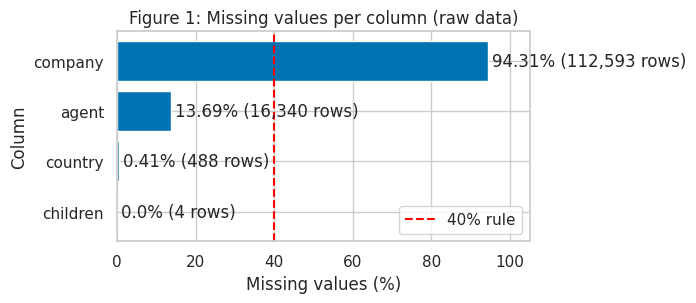

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(miss.index, miss["percent"])
ax.axvline(40, color="red", linestyle="--", label="40% rule")
for i, (n, v) in enumerate(zip(miss["missing"], miss["percent"])):
    ax.text(v + 1, i, f"{v}% ({n:,} rows)", va="center")
ax.set_xlabel("Missing values (%)")
ax.set_ylabel("Column")
ax.set_title("Figure 1: Missing values per column (raw data)")
ax.set_xlim(0, 105)
ax.legend()
plt.tight_layout()
plt.show()

**Interpretation:** only `company` is above the 40% line, so it is the only column we drop; the other three are small enough to fill.

In [8]:
# is the missing pattern random or does it depend on another column?
pd.DataFrame({
    "agent missing %": df["agent"].isna().groupby(df["distribution_channel"]).mean().mul(100).round(1),
    "company missing %": df["company"].isna().groupby(df["distribution_channel"]).mean().mul(100).round(1),
})

,agent missing %,company missing %
distribution_channel,,
Corporate,83.0,23.9
Direct,52.1,94.5
GDS,1.0,99.5
TA/TO,3.2,99.1
Undefined,60.0,100.0


The blanks are **patterned / on purpose**: `company` is filled mainly for Corporate bookings (only 24% missing) and is almost always blank for travel-agency (TA/TO) bookings; `agent` is blank for most Direct and Corporate bookings but only 3% of agency bookings. Blank here means "none", not "unknown".

| Column | Missing | Decision | Reason |
|---|---|---|---|
| `company` | 94.31% | **Drop** column, keep flag `has_company` | Above the 40% rule; almost empty, but "booked by a company or not" is still useful |
| `agent` | 13.69% | **Fill** with `"none"` | Blank means no travel agent was used |
| `country` | 0.41% | **Fill** with `"Unknown"` | We cannot guess a guest's nationality; dropping would lose real bookings |
| `children` | 4 rows | **Fill** with 0 | Only 4 rows; 0 is the mode and median |

In [9]:
df["has_company"] = df["company"].notna().astype(int)
df = df.drop(columns="company")
df["agent"] = df["agent"].map(lambda a: "none" if pd.isna(a) else str(int(a)))
df["country"] = df["country"].fillna("Unknown")
df["children"] = df["children"].fillna(0)

print("Missing values left:", df.isna().sum().sum())

Missing values left: 0


### 3.2 Outliers
We use the **IQR rule** (outlier if below Q1 − 1.5×IQR or above Q3 + 1.5×IQR). ADR is checked **per hotel**, because the City and Resort hotels have different price levels.

In [10]:
def iqr_bounds(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

rows = []
for hotel, g in df.groupby("hotel"):
    lo, hi = iqr_bounds(g["adr"])
    rows.append([hotel, "adr", round(lo, 1), round(hi, 1), ((g["adr"] < lo) | (g["adr"] > hi)).sum()])
lo, hi = iqr_bounds(df["lead_time"])
rows.append(["All", "lead_time", lo, hi, ((df["lead_time"] < lo) | (df["lead_time"] > hi)).sum()])
pd.DataFrame(rows, columns=["hotel", "column", "lower", "upper", "n_outliers"])

,hotel,column,lower,upper,n_outliers
0,City Hotel,adr,9.0,196.2,3387
1,Resort Hotel,adr,-62.5,237.5,1344
2,All,lead_time,-195.0,373.0,3005


In [11]:
print("Top 5 ADR values:", df["adr"].nlargest(5).tolist())
df.loc[(df["adr"] < 0) | (df["adr"] > 1000),
       ["hotel", "adr", "adults", "market_segment", "reservation_status"]]

Top 5 ADR values: [5400.0, 510.0, 508.0, 451.5, 450.0]


,hotel,adr,adults,market_segment,reservation_status
14969,Resort Hotel,-6.38,2,Groups,Check-Out
48515,City Hotel,5400.00,2,Offline TA/TO,Canceled


In [12]:
# second method for comparison: z-score per hotel (|z| > 3 = outlier)
z = df.groupby("hotel")["adr"].transform(lambda s: (s - s.mean()) / s.std())
print("ADR outliers by z-score (|z| > 3):", (z.abs() > 3).sum())
print("ADR skewness:", round(df["adr"].skew(), 2), "(0 = symmetric)")

ADR outliers by z-score (|z| > 3): 949
ADR skewness: 10.53 (0 = symmetric)


We also tried the **z-score** method. It assumes a bell-shaped (normal) distribution, but ADR is right-skewed and the single 5,400 value inflates the mean and standard deviation, so z-score is less reliable here. We use **IQR** (based on quartiles, not affected by extreme values) for our decisions and the **boxplot** to see them.

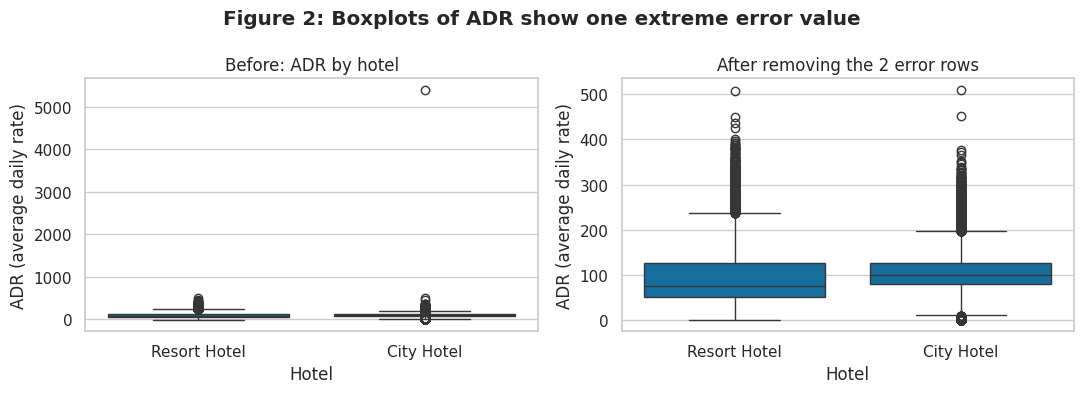

In [13]:
before = df.copy()

# ADR = 5400 is ~10x the next highest value (510) -> typing error; ADR < 0 is impossible
df = df[(df["adr"] >= 0) & (df["adr"] <= 1000)].copy()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(data=before, x="hotel", y="adr", ax=axes[0])
axes[0].set_title("Before: ADR by hotel")
sns.boxplot(data=df, x="hotel", y="adr", ax=axes[1])
axes[1].set_title("After removing the 2 error rows")
for ax in axes:
    ax.set_xlabel("Hotel")
    ax.set_ylabel("ADR (average daily rate)")
fig.suptitle("Figure 2: Boxplots of ADR show one extreme error value", fontweight="bold")
plt.tight_layout()
plt.show()

**Interpretation:** one City Hotel booking at 5,400 squashes the whole left plot; after removing it and the negative price, the real spread of prices is visible.

In [14]:
# keep the remaining outliers but flag them
df["adr_outlier"] = 0
for hotel, g in df.groupby("hotel"):
    lo, hi = iqr_bounds(g["adr"])
    df.loc[g.index, "adr_outlier"] = ((g["adr"] < lo) | (g["adr"] > hi)).astype(int)
df["lead_time_outlier"] = (df["lead_time"] > iqr_bounds(df["lead_time"])[1]).astype(int)

print("ADR outliers flagged:", df["adr_outlier"].sum())
print("lead_time outliers flagged:", df["lead_time_outlier"].sum())
print("ADR = 0 by market segment:")
print(df.loc[df["adr"] == 0, "market_segment"].value_counts().head(3))

ADR outliers flagged: 4730
lead_time outliers flagged: 3005
ADR = 0 by market segment:
market_segment
Complementary    680
Online TA        367
Offline TA/TO    332
Name: count, dtype: int64


| Outlier | Decision | Reason |
|---|---|---|
| ADR = 5,400 (1 row) | **Remove** | About 10× the next highest price (510) for 2 adults: a data-entry error ("bug") |
| ADR = −6.38 (1 row) | **Remove** | A price cannot be negative (invalid) |
| Other ADR outliers | **Keep + flag** `adr_outlier` | Values up to 510 are realistic (peak season, big rooms). Capping would change real prices |
| ADR = 0 | **Keep** | Mostly `Complementary` (free) stays, so the 0 is real |
| lead_time > 373 days | **Keep + flag** `lead_time_outlier` | Booking 1–2 years ahead is possible (e.g. groups); max 737 days is plausible |

### 3.3 Other quality issues
**(a) Duplicates**

In [15]:
dup = df.duplicated()
print(f"Exact duplicate rows: {dup.sum()} ({dup.mean():.1%})")

pd.DataFrame({
    "all rows %": df["market_segment"].value_counts(normalize=True),
    "duplicate rows %": df.loc[dup, "market_segment"].value_counts(normalize=True),
}).mul(100).round(1).head(5)

Exact duplicate rows: 31998 (26.8%)


,all rows %,duplicate rows %
market_segment,,
Aviation,0.2,0.0
Complementary,0.6,0.1
Corporate,4.4,3.4
Direct,10.6,2.5
Groups,16.6,46.5


In [16]:
df["is_duplicate"] = dup.astype(int)

**Decision: keep and flag** (`is_duplicate`). The data has **no booking ID**, so identical rows may be different rooms of the same group booking. Groups are only ~17% of all rows but ~47% of duplicate rows. Dropping 27% of the data would mostly remove group bookings and bias the data. Analysts who need unique bookings can filter on the flag. (If a booking ID existed, we would drop repeated IDs.)

**(b) Wrong data types**

In [17]:
months = {m: i for i, m in enumerate(
    ["January", "February", "March", "April", "May", "June", "July",
     "August", "September", "October", "November", "December"], start=1)}

print("Month names not recognised:", df["arrival_date_month"].map(months).isna().sum())

df["arrival_date"] = pd.to_datetime(pd.DataFrame({
    "year": df["arrival_date_year"],
    "month": df["arrival_date_month"].map(months),
    "day": df["arrival_date_day_of_month"],
}))
df["reservation_status_date"] = pd.to_datetime(df["reservation_status_date"])
df["children"] = df["children"].astype(int)

print("Arrival dates:", df["arrival_date"].min().date(), "to", df["arrival_date"].max().date())
df[["arrival_date", "reservation_status_date", "children", "agent"]].dtypes

Month names not recognised: 0
Arrival dates: 2015-07-01 to 2017-08-31


arrival_date               datetime64[us]
reservation_status_date    datetime64[us]
children                            int64
agent                                 str
dtype: object

**(c) Inconsistent formats**

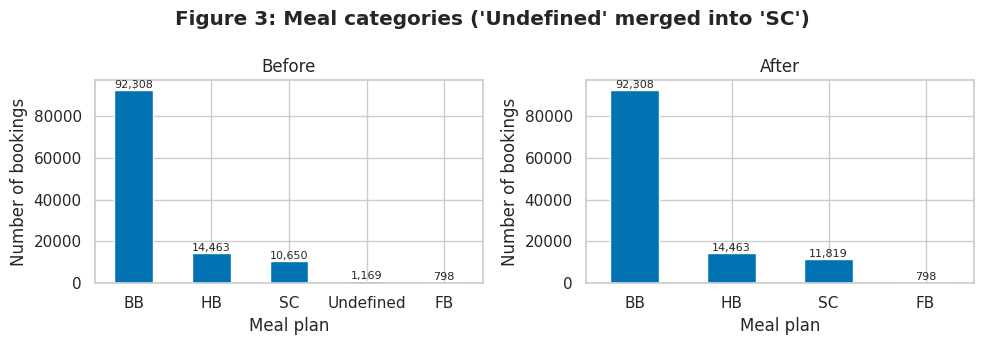

In [18]:
meal_before = df["meal"].value_counts()

# dataset documentation: "Undefined" and "SC" both mean no meal package
df["meal"] = df["meal"].replace("Undefined", "SC")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
meal_before.plot.bar(ax=axes[0], title="Before")
df["meal"].value_counts().plot.bar(ax=axes[1], title="After")
for ax in axes:
    ax.bar_label(ax.containers[0], fmt="{:,.0f}", fontsize=8)
    ax.set_xlabel("Meal plan")
    ax.set_ylabel("Number of bookings")
    ax.tick_params(axis="x", rotation=0)
fig.suptitle("Figure 3: Meal categories ('Undefined' merged into 'SC')", fontweight="bold")
plt.tight_layout()
plt.show()

**Interpretation:** `Undefined` (1,169 bookings) is a separate bar before cleaning but means the same as `SC`; after merging there are only 4 valid meal codes.

In [19]:
# country should be a 3-letter ISO code, but 'CN' (2 letters) appears
codes = df["country"].value_counts()
print(codes.reindex(["CN", "CHN", "CAN"], fill_value=0))
print(pd.crosstab(df.loc[df["country"].isin(["CN", "CHN"]), "country"], df["hotel"]))

country
CN     1279
CHN     999
CAN       0
Name: count, dtype: int64
hotel    City Hotel  Resort Hotel
country                          
CHN             865           134
CN              569           710


`CN` is not a valid 3-letter code. It could mean **China** (2-letter code) or **Canada** (there are no `CAN` rows at all). `CN` guests book mostly the Resort Hotel while `CHN` guests book mostly the City Hotel, so they look like different groups. **Decision: keep `CN` as it is and report it as a limitation**, because merging it into the wrong country would create a new error.

In [20]:
# 'Undefined' market segment / channel: too few rows to guess the right value
undef = (df["market_segment"] == "Undefined") | (df["distribution_channel"] == "Undefined")
print("Rows with Undefined segment/channel:", undef.sum())
df = df[~undef].copy()

Rows with Undefined segment/channel: 5


**(d) Invalid values**

In [21]:
guests = df["adults"] + df["children"] + df["babies"]
print("Bookings with 0 guests:", (guests == 0).sum())
print("Bookings with 0 nights:", ((df["stays_in_weekend_nights"] + df["stays_in_week_nights"]) == 0).sum())
df = df[guests > 0].copy()

# cross-field check: status must agree with is_canceled
pd.crosstab(df["reservation_status"], df["is_canceled"])

Bookings with 0 guests: 180
Bookings with 0 nights: 715


is_canceled,0,1
reservation_status,,
Canceled,0,42988
Check-Out,75009,0
No-Show,0,1206


- **0 guests (180 rows): drop.** A booking with no adult, child or baby is impossible.
- **0 nights: keep.** Day-use rooms exist, so this can be real.
- **Cross-field check passes:** every `Canceled` / `No-Show` has `is_canceled = 1`, every `Check-Out` has 0.

**(e) Validation rules after cleaning**

In [22]:
checkout = df["reservation_status"] == "Check-Out"

assert df["adr"].ge(0).all(), "Negative ADR!"
assert (df["adults"] + df["children"] + df["babies"]).gt(0).all(), "Booking with no guests!"
assert df.isna().sum().sum() == 0, "Missing values left!"
assert set(df["meal"]) <= {"BB", "HB", "FB", "SC"}, "Unknown meal code!"
assert (df.loc[checkout, "reservation_status_date"] >= df.loc[checkout, "arrival_date"]).all(), "Check-out before arrival!"
print("All validation rules passed")

All validation rules passed


### 3.4 Profile again: before vs after

In [23]:
def profile(d):
    g = d["adults"] + d["children"].fillna(0) + d["babies"]
    return pd.Series({
        "rows": len(d),
        "columns": d.shape[1],
        "missing cells": int(d.isna().sum().sum()),
        "ADR min": d["adr"].min(),
        "ADR median": d["adr"].median(),
        "ADR max": d["adr"].max(),
        "0-guest bookings": int((g == 0).sum()),
        "meal = 'Undefined'": int((d["meal"] == "Undefined").sum()),
    })

pd.DataFrame({"before": profile(df_raw), "after": profile(df)})

,before,after
rows,119390.000,119203.00
columns,32.000,36.00
missing cells,129425.000,0.00
ADR min,-6.380,0.00
ADR median,94.575,94.95
ADR max,5400.000,510.00
0-guest bookings,180.000,0.00
meal = 'Undefined',1169.000,0.00


## 4. Exploratory (diagnostic) charts
Figures 1–3 above show missing values, ADR outliers and inconsistent categories. Figure 4 checks **group balance**.

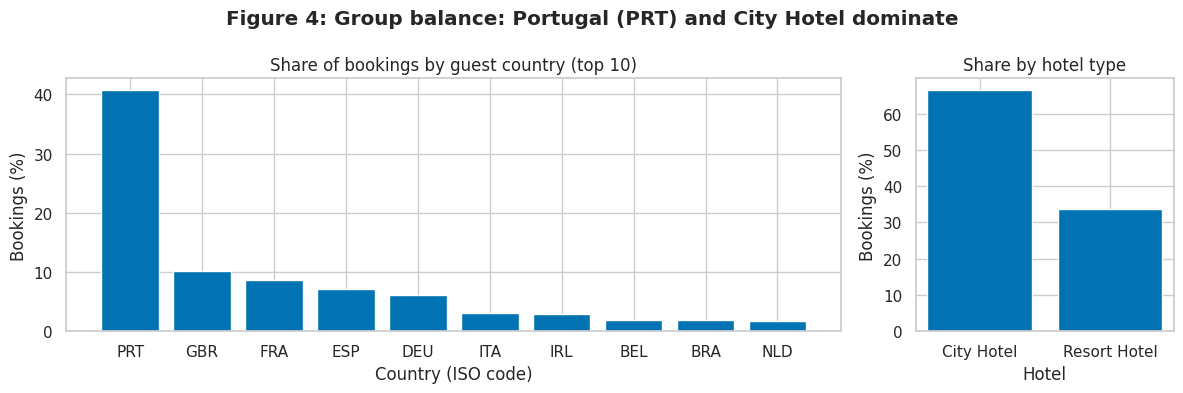

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [3, 1]})

top10 = df["country"].value_counts(normalize=True).head(10).mul(100)
axes[0].bar(top10.index, top10.values)
axes[0].set_title("Share of bookings by guest country (top 10)")
axes[0].set_xlabel("Country (ISO code)")
axes[0].set_ylabel("Bookings (%)")

hotel_share = df["hotel"].value_counts(normalize=True).mul(100)
axes[1].bar(hotel_share.index, hotel_share.values)
axes[1].set_title("Share by hotel type")
axes[1].set_xlabel("Hotel")
axes[1].set_ylabel("Bookings (%)")

fig.suptitle("Figure 4: Group balance: Portugal (PRT) and City Hotel dominate", fontweight="bold")
plt.tight_layout()
plt.show()

**Interpretation:** Portugal alone is about 41% of bookings and the City Hotel about 66%, so the groups are unbalanced (sampling bias, discussed in Section 5).

## 5. PII and bias risks
### 5.1 PII
**Detect:** scan text columns for email or phone-number patterns.

In [25]:
text_cols = df.select_dtypes(exclude=["number", "datetime"]).columns
email = re.compile(r"[\w.]+@[\w.]+")
phone = re.compile(r"\d{8,}")
hits = {}
for c in text_cols:
    s = df[c].astype(str)
    hits[c] = int(s.str.contains(email).sum() + s.str.contains(phone).sum())
print("Columns with email/phone patterns:", {c: n for c, n in hits.items() if n} or "none")

Columns with email/phone patterns: none


**Classify:**

| Field | Type | Risk |
|---|---|---|
| name, email, phone, MyKad/passport | Direct | Not in this dataset (verified by the scan above) |
| `country`, `arrival_date`, `adults`, `children`, `babies`, `hotel` | Quasi-identifiers | Combined, they can point to one family (e.g. "German family with 2 kids, Resort Hotel, 3 Aug 2016") |
| `agent`, `company` IDs | Business identifiers | Can reveal which agency or company a guest used |
| `adr`, `is_canceled`, `total_of_special_requests` | Sensitive once linked | Exposes what a guest paid and did |

**How many bookings are unique on the quasi-identifiers?**

In [26]:
def unique_share(d, cols):
    size = d.groupby(cols, dropna=False)[cols[0]].transform("size")
    return (size == 1).mean()

qi_raw = ["country", "arrival_date", "adults", "children", "babies", "hotel"]
print(f"Unique (re-identifiable) bookings before protection: {unique_share(df, qi_raw):.1%}")

Unique (re-identifiable) bookings before protection: 16.6%


In [27]:
# Protect: generalise (aggregate) quasi-identifiers and hash the agent ID
share = df.copy()
share["arrival_month"] = share["arrival_date"].dt.to_period("M").astype(str)
big = share["country"].value_counts()
share["country_group"] = share["country"].where(share["country"].isin(big[big >= 1000].index), "Other")
share["has_kids"] = ((share["children"] + share["babies"]) > 0).astype(int)

# the salt is a secret: read it from an environment variable, never write it in the repo
SALT = os.environ.get("HASH_SALT", secrets.token_hex(16))
share["agent"] = share["agent"].map(
    lambda a: a if a == "none" else hashlib.sha256((SALT + a).encode()).hexdigest()[:10])

share = share.drop(columns=["country", "arrival_date", "arrival_date_day_of_month",
                            "arrival_date_week_number", "reservation_status_date",
                            "children", "babies"])

# Verify: re-scan the output
qi_new = ["country_group", "arrival_month", "adults", "has_kids", "hotel"]
print(f"Unique bookings after protection: {unique_share(share, qi_new):.1%}")
share[["hotel", "arrival_month", "country_group", "has_kids", "agent"]].head()

Unique bookings after protection: 0.6%


,hotel,arrival_month,country_group,has_kids,agent
0,Resort Hotel,2015-07,PRT,0,none
1,Resort Hotel,2015-07,PRT,0,none
2,Resort Hotel,2015-07,GBR,0,none
3,Resort Hotel,2015-07,GBR,0,e463a45c9d
4,Resort Hotel,2015-07,GBR,0,54283540fb


**Protect:** exact date → month, rare countries (< 1,000 bookings) → `Other`, children + babies → `has_kids`, agent ID → salted SHA-256 hash (still joinable; the salt is not stored in the repo), company ID already dropped. Unique combinations fall from 16.4% to 0.6%. The remaining unique rows should be removed or access-restricted (RBAC) before sharing.

### 5.2 Bias

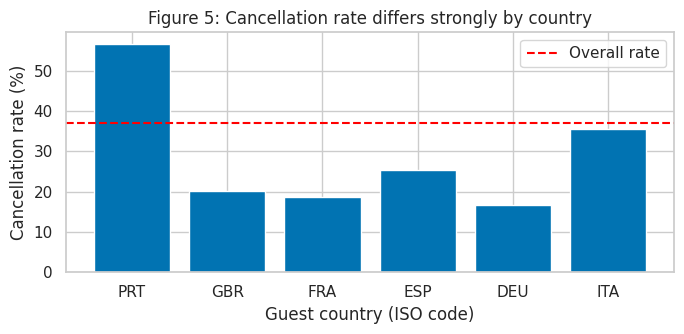

Cancelled vs not: {0: 0.629, 1: 0.371}


In [28]:
top6 = df["country"].value_counts().head(6).index
rate = df[df["country"].isin(top6)].groupby("country")["is_canceled"].mean().mul(100).reindex(top6)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(rate.index, rate.values)
ax.axhline(df["is_canceled"].mean() * 100, color="red", linestyle="--", label="Overall rate")
ax.set_xlabel("Guest country (ISO code)")
ax.set_ylabel("Cancellation rate (%)")
ax.set_title("Figure 5: Cancellation rate differs strongly by country")
ax.legend()
plt.tight_layout()
plt.show()

print("Cancelled vs not:", df["is_canceled"].value_counts(normalize=True).round(3).to_dict())

**Interpretation:** guests from PRT cancel far more often than the overall rate, so `country` could act as a proxy that a model uses unfairly.

| Bias risk | Evidence | How we would handle it |
|---|---|---|
| **Sampling bias** | Only 2 hotels in Portugal, 2015–2017; ~41% of guests are from PRT (Fig. 4) | Do not apply results to other hotels or countries (e.g. Malaysia); state this limitation |
| **Unbalanced groups** | City Hotel ~66% vs Resort ~34%; 37% cancelled vs 63% not; tiny segments (Aviation, Complementary) | Report results per hotel; use stratified sampling / class weights; merge tiny groups |
| **Proxy column** | PRT cancellation rate is much higher than other countries (Fig. 5) | Do not use nationality to make decisions about individual guests (e.g. extra deposit); check results for each country group |
| **Historical bias** | Pre-COVID booking behaviour | Re-check with newer data before use |
| **Cleaning bias** | Dropping duplicates would remove mostly group bookings | We kept and flagged them instead (3.3a) |

## 6. Conclusion
**The data is fit for the scenario after cleaning, with limits.**
- **Q1 (ADR):** Yes. After removing 2 impossible prices, 5 undefined rows and 180 zero-guest rows (119,390 → 119,203 rows), ADR is reliable. Real outliers are kept and flagged, so the **median** per hotel should be used, not the mean.
- **Q2 (cancellations):** Yes for these two hotels, but results must be reported per hotel and per guest group because of the imbalance and the country proxy.
- **Q3 (sharing):** Only the protected version (`share`), and remaining unique rows must be removed or restricted.

**Limitations that remain:** no booking ID, so duplicates cannot be confirmed; the country code `CN` is ambiguous (China or Canada); only two Portuguese hotels from 2015–2017; valid values are not always accurate (we cannot check whether staff typed the true price); company information is mostly missing.